In [2]:
import math

from PIL import Image
import requests
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

import ipywidgets as widgets
from IPython.display import display, clear_output

import torch
from torch import nn
from torchvision.models import resnet50
import torchvision.transforms as T
torch.set_grad_enabled(False);

In [3]:
CLASSES = [
    'N/A', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A',
    'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse',
    'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack',
    'umbrella', 'N/A', 'N/A', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis',
    'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
    'skateboard', 'surfboard', 'tennis racket', 'bottle', 'N/A', 'wine glass',
    'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich',
    'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table', 'N/A',
    'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard',
    'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A',
    'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier',
    'toothbrush'
]

# colors for visualization
COLORS = [[0.000, 0.447, 0.741], [0.850, 0.325, 0.098], [0.929, 0.694, 0.125],
          [0.494, 0.184, 0.556], [0.466, 0.674, 0.188], [0.301, 0.745, 0.933]]

In [4]:
# standard PyTorch mean-std input image normalization
transform = T.Compose([
    T.Resize((800, 800)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# for output bounding box post-processing
def box_cxcywh_to_xyxy(x):
    x_c, y_c, w, h = x.unbind(1)
    b = [(x_c - 0.5 * w), (y_c - 0.5 * h),
         (x_c + 0.5 * w), (y_c + 0.5 * h)]
    return torch.stack(b, dim=1)

def rescale_bboxes(out_bbox, size):
    img_w, img_h = size
    b = box_cxcywh_to_xyxy(out_bbox)
    b = b * torch.tensor([img_w, img_h, img_w, img_h], dtype=torch.float32)
    return b

def plot_results(pil_img, prob, boxes):
    plt.figure(figsize=(16,10))
    plt.imshow(pil_img)
    ax = plt.gca()
    colors = COLORS * 100
    for p, (xmin, ymin, xmax, ymax), c in zip(prob, boxes.tolist(), colors):
        ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                   fill=False, color=c, linewidth=3))
        cl = p.argmax()
        text = f'{CLASSES[cl]}: {p[cl]:0.2f}'
        ax.text(xmin, ymin, text, fontsize=15,
                bbox=dict(facecolor='yellow', alpha=0.5))
    plt.axis('off')
    plt.show()

In [5]:
from data.dataloader import RefL4Dataset

dataset = RefL4Dataset(
    dataset_path='./dataset/refl4',
    split="val",
    load_images=True,
    load_features=False,
    custom_transforms=transform,
)

In [6]:
model = torch.hub.load('facebookresearch/detr', 'detr_resnet50', pretrained=True)
model.eval();

Using cache found in /home/thle/.cache/torch/hub/facebookresearch_detr_main
/mlbio_scratch/thle/bin/thle/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mlbio_scratch/thle/bin/thle/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [7]:
image_file = dataset[1]["image_file"]
processed_image = dataset[1]["image"]

In [25]:
gt_bbox = dataset[1]["bbox"]
gt_bbox 

# convert from xywh to xyxy format
x,y,w,h = gt_bbox
gt_bbox = [x, y, x+w, y+h]
gt_bbox

[tensor(395.8182), tensor(417.6211), tensor(611.4456), tensor(753.7784)]

In [8]:
im = Image.open(image_file)

# mean-std normalize the input image (batch-size: 1)
# img = transform(im).unsqueeze(0)

# propagate through the model
outputs = model(processed_image.unsqueeze(0))

# keep only predictions with 0.7+ confidence
probas = outputs['pred_logits'].softmax(-1)[0, :, :-1]
keep = probas.max(-1).values > 0.9

# convert boxes from [0; 1] to image scales
bboxes_scaled = rescale_bboxes(outputs['pred_boxes'][0, keep], im.size)

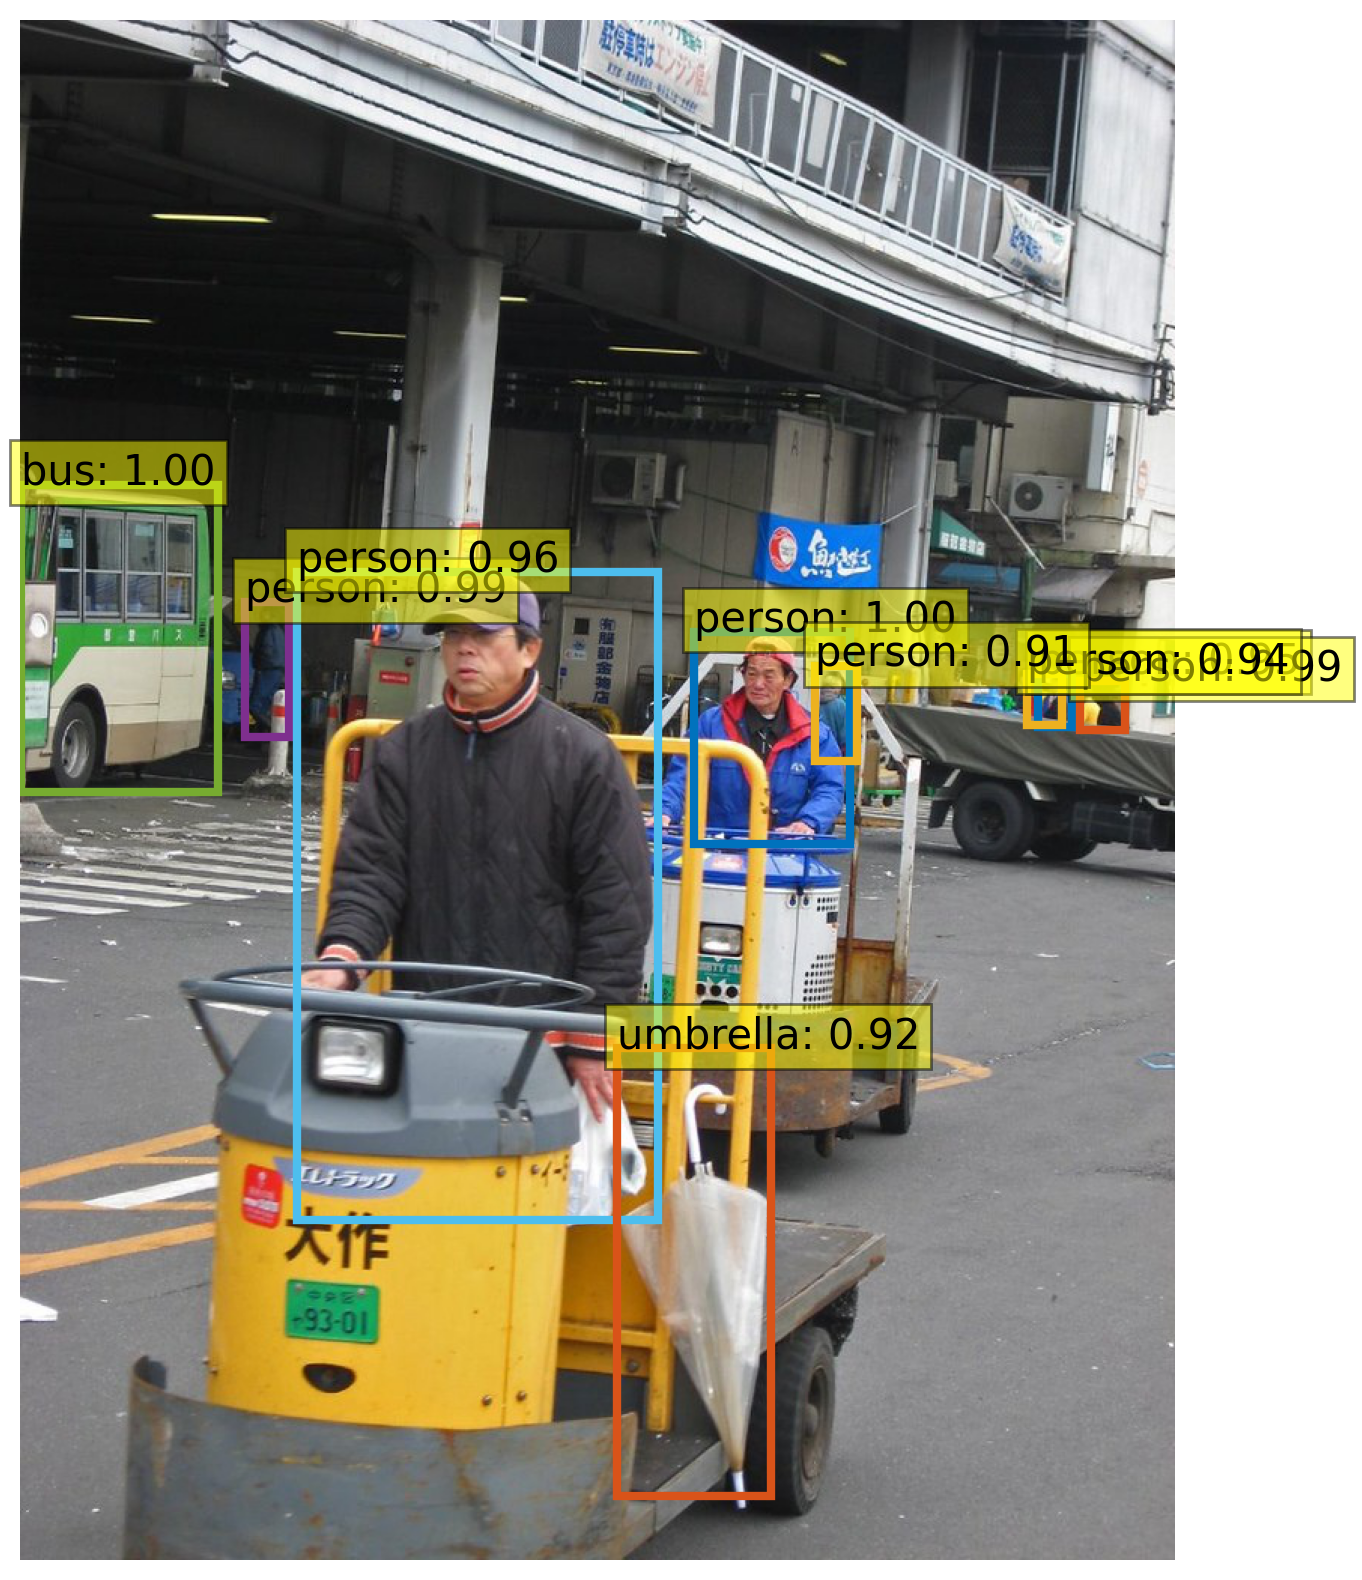

In [9]:
plot_results(im, probas[keep], bboxes_scaled)

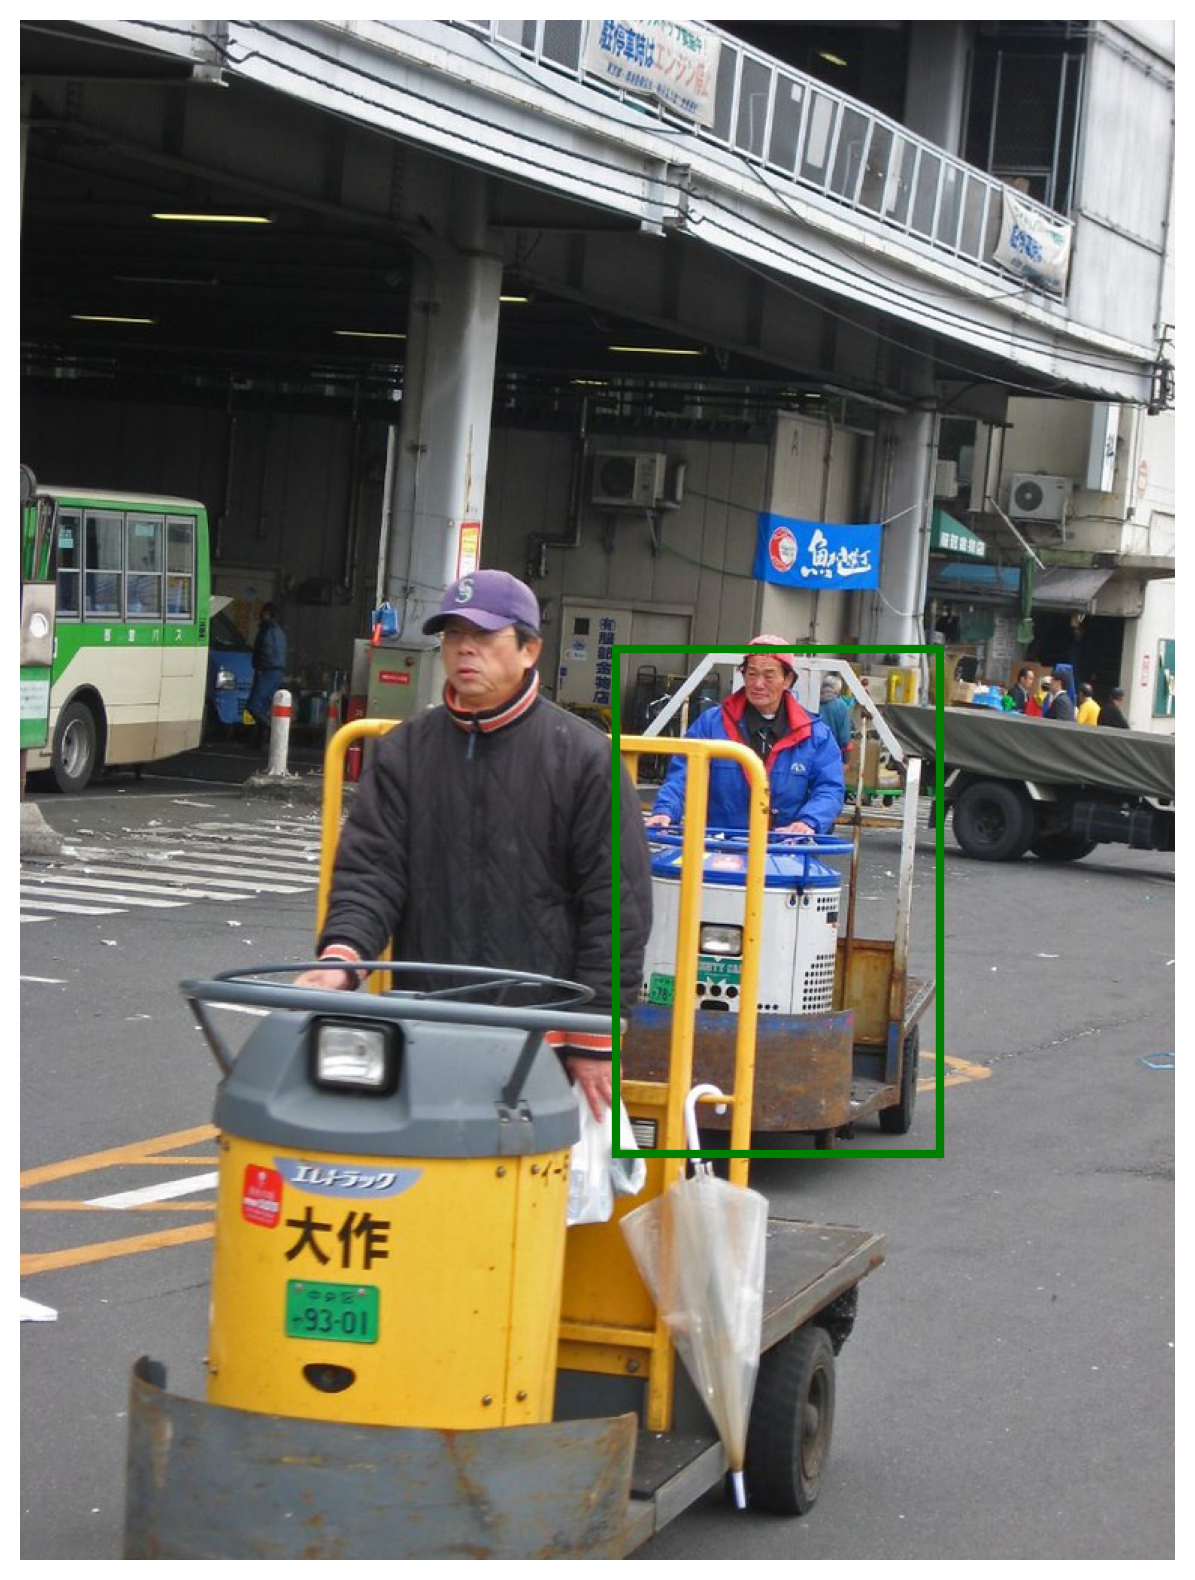

In [29]:
# Plot ground truth
def plot_gt(pil_img, box):
    plt.figure(figsize=(16,10))
    plt.imshow(pil_img)
    ax = plt.gca()
    
    xmin, ymin, xmax, ymax = box
    ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                   fill=False, color="green", linewidth=3))
    plt.axis('off')
    plt.show()
    
plot_gt(im, gt_bbox)

In [10]:
dataset.transforms

Compose(
    Resize(size=(800, 800), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

In [ ]:
import torch
from torchvision.ops import box_iou
from tqdm import tqdm

def box_cxcywh_to_xyxy(boxes):
    # boxes: [num_boxes, 4] with cx, cy, w, h
    x_c, y_c, w, h = boxes.unbind(1)
    b = [(x_c - 0.5 * w), (y_c - 0.5 * h),
         (x_c + 0.5 * w), (y_c + 0.5 * h)]
    return torch.stack(b, dim=1)

def box_xywh_to_xyxy(box):
    # Convert [x, y, w, h] to [x1, y1, x2, y2]
    x, y, w, h = box.unbind(1)
    return torch.stack((x, y, x + w, y + h), dim=1)

@torch.no_grad()
def evaluate_detr(model, dataloader, device, iou_threshold=0.5, score_threshold=0.7):
    model.eval()
    model.to(device)

    total_true_positives = 0
    total_predictions = 0
    total_ground_truths = 0

    for batch in tqdm(dataloader):
        images = batch["image"].to(device)  # [B, 3, H, W]
        bboxes = batch["bbox"].to(device)   # [B, 4]
        labels = batch["label"].to(device)  # [B]

        outputs = model(images)
        
        # import pdb; pdb.set_trace()

        for i in range(len(images)):
            pred_logits = outputs["pred_logits"][i].softmax(-1)[:, :-1]  # remove no-object class
            pred_boxes = outputs["pred_boxes"][i]  # [num_queries, 4], normalized cxcywh
            print(pred_boxes.shape)
            
            scores, pred_labels = pred_logits.max(-1)
            keep = scores > score_threshold
            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]

            pred_boxes = box_cxcywh_to_xyxy(pred_boxes)
            # Unnormalize
            H, W = images[i].shape[-2:]
            scale = torch.tensor([W, H, W, H], dtype=torch.float32).to(device)
            pred_boxes = pred_boxes * scale

            gt_box = box_xywh_to_xyxy(bboxes[i].unsqueeze(0))  # [1, 4]
            total_ground_truths += 1
            total_predictions += len(pred_boxes)

            if len(pred_boxes) == 0:
                continue

            ious = box_iou(pred_boxes, gt_box)  # [num_preds, 1]
            matches = (ious > iou_threshold).sum().item()
            total_true_positives += matches

    precision = total_true_positives / total_predictions if total_predictions > 0 else 0
    recall = total_true_positives / total_ground_truths if total_ground_truths > 0 else 0

    return {
        "precision": precision,
        "recall": recall,
        "true_positives": total_true_positives,
        "total_predictions": total_predictions,
        "total_ground_truths": total_ground_truths
    }


In [21]:
from torch.utils.data import DataLoader
    
dataloader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
)

eval_results = evaluate_detr(
    model,
    dataloader,
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    iou_threshold=0.5,
    score_threshold=0.7
)

100%|██████████| 142/142 [08:33<00:00,  3.62s/it]


In [22]:
eval_results

{'precision': 0.0025250960465980914,
 'recall': 0.03595059550066167,
 'true_positives': 163,
 'total_predictions': 64552,
 'total_ground_truths': 4534}